In [1]:
from google.colab import files
uploaded= files.upload()

Saving superstore_sample.csv to superstore_sample.csv


In [2]:
import pandas as pd
import numpy as np
df=pd.read_csv('superstore_sample.csv')
df.head()

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Region,State,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,ORD-2024-00887,04-05-2024,08-05-2024,Second Class,CU-0087,Corporate,East,New York,Furniture,Chairs,Chairs Product 10,270.25,2,0.0,14.55
1,ORD-2024-00285,13-11-2024,20-11-2024,Standard Class,CU-0380,Corporate,West,Oregon,Office Supplies,Art,Art Product 6,198.15,9,0.0,41.71
2,ORD-2024-00459,24-11-2024,24-11-2024,Same Day,CU-0434,Home Office,East,New York,Technology,Copiers,Copiers Product 12,2673.04,2,NaN,373.35
3,ORD-2025-00456,22-10-2025,27-10-2025,Standard Class,CU-0167,Home Office,South,Virginia,Furniture,Furnishings,Furnishings Product 11,347.30,9,0.0,50.31
4,ORD-2024-01325,27-06-2024,02-07-2024,Standard Class,CU-0360,Corporate,East,New York,Office Supplies,Labels,Labels Product 7,142.09,9,0.0,56.87


## Data cleaning log:

- **Duplicate rows:** Removed 25 exact duplicates so repeated records are not counted twice.
- **Ship Mode spelling/capitalization:** Trimmed extra spaces and standardized capitalization so equivalent labels group together.
- **Date format:** The CSV uses day-month-year dates (for example, `04-05-2024`). Parsed dates with `dayfirst=True`; without it, many valid dates became missing and were filled with the median date, creating a false sales spike in the chart.
- **Missing Profit:** Dropped 15 remaining rows with missing Profit because profit cannot be reliably inferred.
- **Other missing values:** Filled missing text values with `Unknown` and missing numeric values with the column median to retain usable rows.
- **Cleaned output:** Saved the cleaned table as `superstore_cleaned.csv` for the charts and SQL analysis.




In [3]:
if 'change_log' not in locals():
    change_log = []

duplicate_count = df.duplicated().sum()
if duplicate_count > 0:
    df = df.drop_duplicates()
    change_log.append(f"Removed {duplicate_count} duplicate rows.")
else:
    change_log.append("No duplicate rows detected.")

In [4]:
if 'Ship Mode' in df.columns:
    original_modes = df['Ship Mode'].unique()
    df['Ship Mode'] = df['Ship Mode'].astype(str).str.title().str.strip()
    new_modes = df['Ship Mode'].unique()
    change_log.append(f"Standardized 'Ship Mode' capitalization. Unique values changed from {original_modes} to {new_modes}.")


In [5]:
date_cols = ['Order Date', 'Ship Date']
for col in date_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], dayfirst=True, errors='coerce')
        missing_dates = df[col].isnull().sum()
        change_log.append(f"Converted '{col}' to datetime. (Detected {missing_dates} unparseable date values).")


In [6]:
missing_summary = df.isnull().sum()
print("\n--- Missing Values Summary (Before Cleaning) ---")
print(missing_summary[missing_summary > 0])



--- Missing Values Summary (Before Cleaning) ---
Segment     10
State       12
Discount    20
Profit      15
dtype: int64


In [7]:
if 'Profit' in df.columns and df['Profit'].isnull().sum() > 0:
    missing_profit_count = df['Profit'].isnull().sum()
    # Dropping rows with missing profit as we shouldn't invent performance metrics
    df = df.dropna(subset=['Profit'])
    change_log.append(f"Dropped {missing_profit_count} rows with missing 'Profit' values to maintain analytical integrity.")


In [8]:
for col in df.columns:
    missing_count = df[col].isnull().sum()
    if missing_count > 0:
        if df[col].dtype == 'object':
            df[col] = df[col].fillna('Unknown')
            change_log.append(f"Filled {missing_count} missing values in '{col}' with 'Unknown'.")
        else:
            df[col] = df[col].fillna(df[col].median())
            change_log.append(f"Filled {missing_count} missing values in '{col}' with column median.")


In [9]:
cleaned_filename = 'superstore_cleaned.csv'
df.to_csv(cleaned_filename, index=False)
change_log.append(f"Saved cleaned dataset to '{cleaned_filename}' with final shape {df.shape}.")

# Display the final log
print("\n--- Cleaning Log ---")
for entry in change_log:
    print(f"- {entry}")

print("\n--- Preview of Cleaned Data ---")
display(df.head())


--- Cleaning Log ---
- Removed 25 duplicate rows.
- Standardized 'Ship Mode' capitalization. Unique values changed from ['Second Class' 'Standard Class' 'Same Day' 'First Class' 'standard class'
 'first class' 'same day' 'second class'] to ['Second Class' 'Standard Class' 'Same Day' 'First Class'].
- Converted 'Order Date' to datetime. (Detected 0 unparseable date values).
- Converted 'Ship Date' to datetime. (Detected 0 unparseable date values).
- Dropped 15 rows with missing 'Profit' values to maintain analytical integrity.
- Filled 9 missing values in 'Segment' with 'Unknown'.
- Filled 12 missing values in 'State' with 'Unknown'.
- Filled 20 missing values in 'Discount' with column median.
- Saved cleaned dataset to 'superstore_cleaned.csv' with final shape (1985, 15).

--- Preview of Cleaned Data ---


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Region,State,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,ORD-2024-00887,2024-05-04,2024-05-08,Second Class,CU-0087,Corporate,East,New York,Furniture,Chairs,Chairs Product 10,270.25,2,0.0,14.55
1,ORD-2024-00285,2024-11-13,2024-11-20,Standard Class,CU-0380,Corporate,West,Oregon,Office Supplies,Art,Art Product 6,198.15,9,0.0,41.71
2,ORD-2024-00459,2024-11-24,2024-11-24,Same Day,CU-0434,Home Office,East,New York,Technology,Copiers,Copiers Product 12,2673.04,2,0.1,373.35
3,ORD-2025-00456,2025-10-22,2025-10-27,Standard Class,CU-0167,Home Office,South,Virginia,Furniture,Furnishings,Furnishings Product 11,347.30,9,0.0,50.31
4,ORD-2024-01325,2024-06-27,2024-07-02,Standard Class,CU-0360,Corporate,East,New York,Office Supplies,Labels,Labels Product 7,142.09,9,0.0,56.87


In [10]:
from google.colab import files

# Download the cleaned file to your local computer
files.download('superstore_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
from google.colab import files
uploaded= files.upload()

Saving superstore_cleaned.csv to superstore_cleaned (1).csv


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv('superstore_cleaned.csv')


In [13]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%Y-%m-%d")
df["Month"] = df["Order Date"].dt.to_period("M").astype(str)

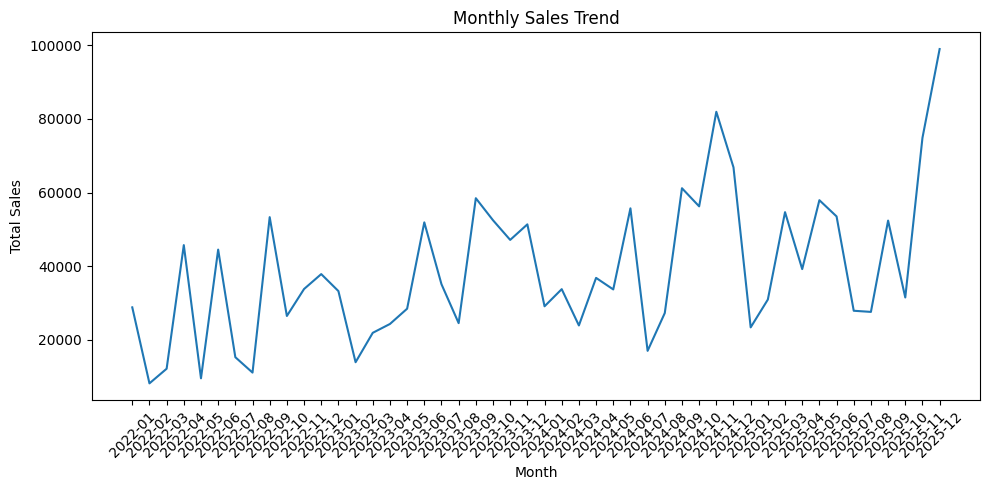

In [14]:
monthly_sales = df.groupby("Month")["Sales"].sum()
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values, )
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Takeaway:** December 2025 had the highest monthly sales at about **$98,962**, showing a strong year-end peak. Plan inventory and promotions ahead of this period, then compare future Decembers to see whether the peak repeats.

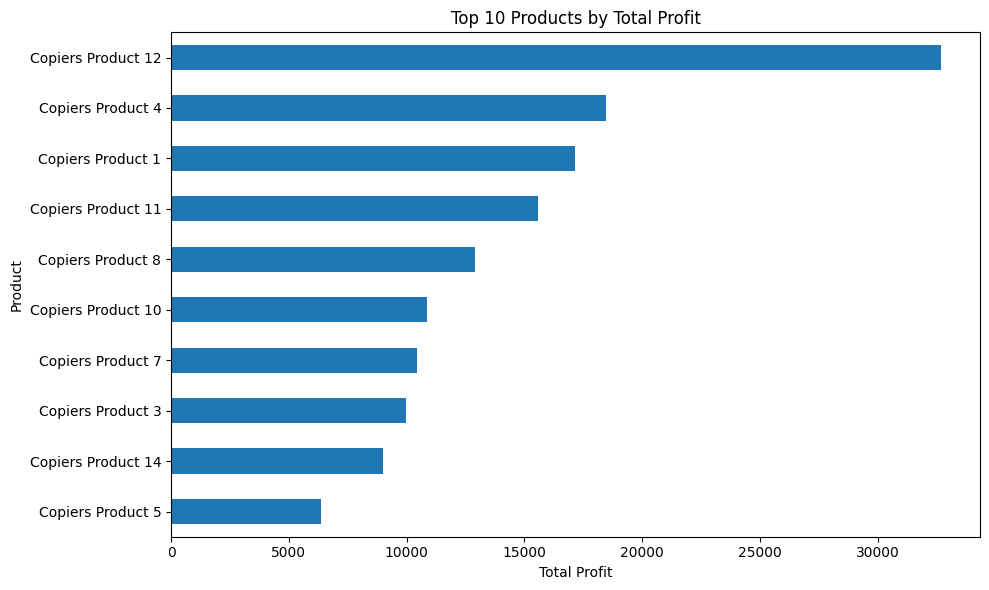

In [15]:
top_products = df.groupby("Product Name")["Profit"].sum().nlargest(10).sort_values()

plt.figure(figsize=(10, 6))
top_products.plot(kind="barh")
plt.title("Top 10 Products by Total Profit")
plt.xlabel("Total Profit")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

**Takeaway:** **Copiers Product 12** earned the highest total profit, about **$32,700**, making it a strong contributor to overall profit. Protect its availability and check whether the same profit holds across regions and months before expanding promotions.

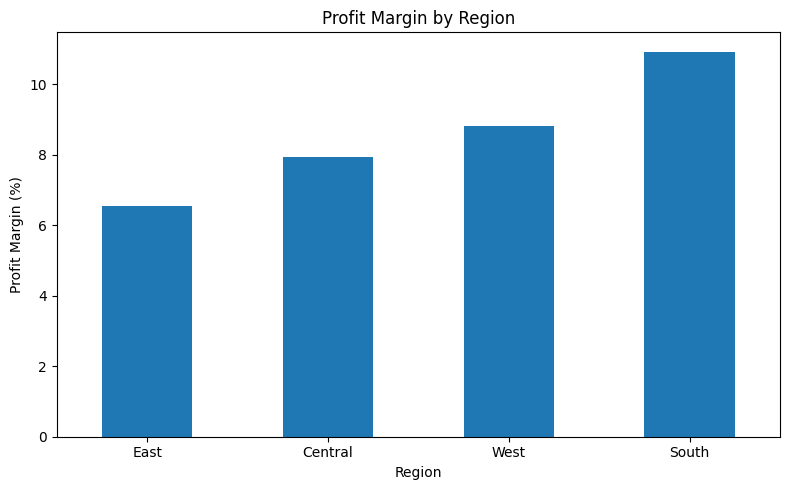

In [16]:
region_margin=(
    df.groupby("Region")["Profit"].sum()
    / df.groupby("Region")["Sales"].sum()
    * 100
).sort_values()
plt.figure(figsize=(8, 5))
region_margin.plot(kind="bar")
plt.title("Profit Margin by Region")
plt.xlabel("Region")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Takeaway:** The **East** had the lowest regional profit margin (**6.56%**) and the **South** the highest (**10.93%**), a gap of **4.37 percentage points**. Review East-region discounts, product mix, and costs to identify changes that could improve margin.